# 03. 探索性数据分析（EDA）

**目标**：从多个维度看销售走势和用户行为，为后续人群分层做铺垫。

**本 notebook 会产出 6 张图，保存到 `../outputs/`**：
1. 月度销售额趋势（含同比）
2. TOP 10 国家销售额（UK 以外）
3. 一周 7 天的订单量分布
4. 一天 24 小时的订单量分布
5. 客户下单次数分布（看长尾）
6. 单客户消费金额分布

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
sns.set_style('whitegrid')

df = pd.read_pickle('../data/retail_clean.pkl')
print('读入形状:', df.shape)
df.head(2)

读入形状: (779425, 14)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice,Year,Month,YearMonth,DayOfWeek,Hour
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,2009,12,2009-12,1,7
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009,12,2009-12,1,7


## 图 1：月度销售额趋势

C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2290430864.py:12: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2290430864.py:12: UserWarning: Glyph 20221 (\N{CJK UNIFIED IDEOGRAPH-4EFD}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2290430864.py:12: UserWarning: Glyph 38144 (\N{CJK UNIFIED IDEOGRAPH-9500}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2290430864.py:12: UserWarning: Glyph 21806 (\N{CJK UNIFIED IDEOGRAPH-552E}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2290430864.py:12: UserWarning: Glyph 39069 (\N{CJK UNIFIED IDEOGRAPH-989D}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2290430864.py:12: UserWarning: Glyph 65288 (\N{FULL

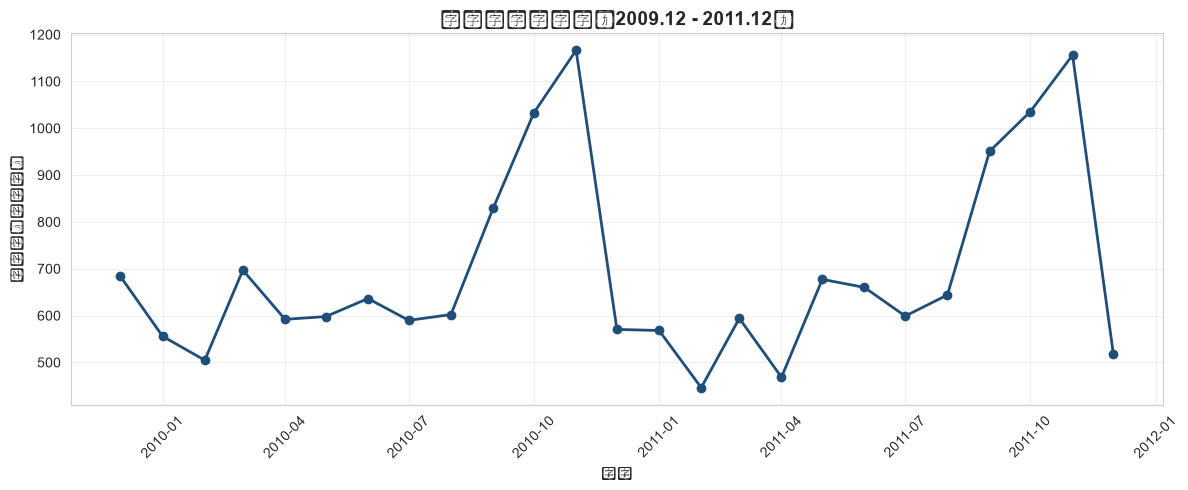


销售额 TOP3 月份:
    YearMonth   TotalPrice
11 2010-11-01  1166460.022
23 2011-11-01  1156205.610
22 2011-10-01  1035642.450


In [2]:
monthly = df.groupby('YearMonth')['TotalPrice'].sum().reset_index()
monthly['YearMonth'] = pd.to_datetime(monthly['YearMonth'])
monthly = monthly.sort_values('YearMonth')

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly['YearMonth'], monthly['TotalPrice'] / 1000, marker='o', linewidth=2, color='#1F4E79')
ax.set_title('月度销售额趋势（2009.12 - 2011.12）', fontsize=14, fontweight='bold')
ax.set_xlabel('月份')
ax.set_ylabel('销售额（千英镑）')
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/01_monthly_sales.png', dpi=150, bbox_inches='tight')
plt.show()

# 打印高峰月份
top_months = monthly.nlargest(3, 'TotalPrice')[['YearMonth', 'TotalPrice']]
print('\n销售额 TOP3 月份:')
print(top_months)

**观察点**：销售额在哪几个月冲高？大概率在 **11 月**（圣诞采购季备货），对礼品批发商是旺季。

## 图 2：TOP 10 国家销售额（UK 以外）

UK 占了 90%+，把它单独放会压扁其他国家，所以这张图**只看非 UK**。

C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2197919871.py:12: UserWarning: Glyph 38144 (\N{CJK UNIFIED IDEOGRAPH-9500}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2197919871.py:12: UserWarning: Glyph 21806 (\N{CJK UNIFIED IDEOGRAPH-552E}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2197919871.py:12: UserWarning: Glyph 39069 (\N{CJK UNIFIED IDEOGRAPH-989D}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2197919871.py:12: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2197919871.py:12: UserWarning: Glyph 21315 (\N{CJK UNIFIED IDEOGRAPH-5343}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2197919871.py:12: UserWarning: Glyph 33521 (\N{CJK 

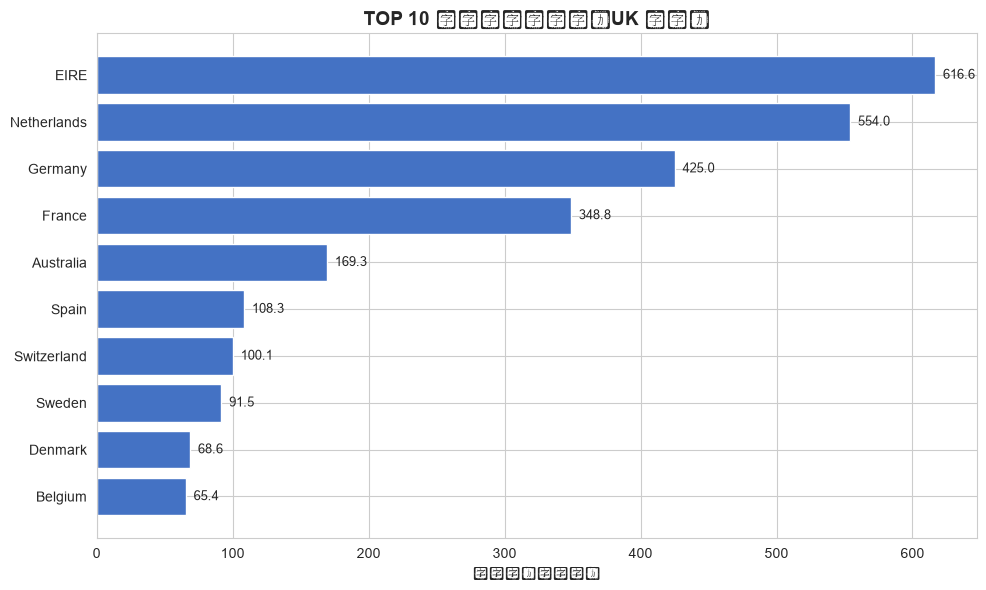


UK 销售额占全局比例: 82.82%


In [3]:
country_sales = (df[df['Country'] != 'United Kingdom']
                 .groupby('Country')['TotalPrice'].sum()
                 .sort_values(ascending=True)
                 .tail(10))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(country_sales.index, country_sales.values / 1000, color='#4472C4')
ax.set_title('TOP 10 海外国家销售额（UK 以外）', fontsize=14, fontweight='bold')
ax.set_xlabel('销售额（千英镑）')
for i, v in enumerate(country_sales.values / 1000):
    ax.text(v, i, f'  {v:.1f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('../outputs/02_top_countries.png', dpi=150, bbox_inches='tight')
plt.show()

# 顺便看一下 UK 占比
uk_share = df[df['Country'] == 'United Kingdom']['TotalPrice'].sum() / df['TotalPrice'].sum()
print(f'\nUK 销售额占全局比例: {uk_share * 100:.2f}%')

## 图 3：一周 7 天的订单量

C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\861614513.py:11: UserWarning: Glyph 21608 (\N{CJK UNIFIED IDEOGRAPH-5468}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\861614513.py:11: UserWarning: Glyph 19968 (\N{CJK UNIFIED IDEOGRAPH-4E00}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\861614513.py:11: UserWarning: Glyph 20108 (\N{CJK UNIFIED IDEOGRAPH-4E8C}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\861614513.py:11: UserWarning: Glyph 19977 (\N{CJK UNIFIED IDEOGRAPH-4E09}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\861614513.py:11: UserWarning: Glyph 22235 (\N{CJK UNIFIED IDEOGRAPH-56DB}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\861614513.py:11: UserWarning: Glyph 20116 (\N{CJK UNIFIE

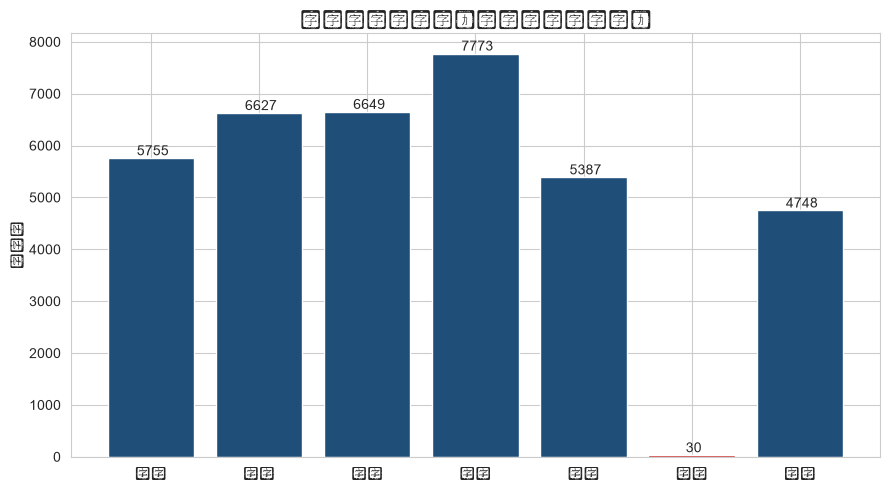


周六订单数: 30 （注意：这是 B2B 批发商，周六可能完全不开门）


In [4]:
dow_order = df.groupby('DayOfWeek')['Invoice'].nunique()
dow_names = ['周一', '周二', '周三', '周四', '周五', '周六', '周日']

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#1F4E79' if i != 5 else '#C00000' for i in range(7)]  # 周六特殊标注
ax.bar(dow_names, dow_order.values, color=colors)
ax.set_title('一周各天订单量（去重后的订单数）', fontsize=14, fontweight='bold')
ax.set_ylabel('订单数')
for i, v in enumerate(dow_order.values):
    ax.text(i, v, f' {v}', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig('../outputs/03_day_of_week.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n周六订单数:', dow_order.get(5, 0), '（注意：这是 B2B 批发商，周六可能完全不开门）')

**观察点**：**周六订单数几乎为 0**——这是一家只在工作日营业的 B2B 批发公司。这个洞察很有商业解读价值，面试讲数据故事能用上。

## 图 4：一天 24 小时的订单量

C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\384136153.py:9: UserWarning: Glyph 23567 (\N{CJK UNIFIED IDEOGRAPH-5C0F}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\384136153.py:9: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\384136153.py:9: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\384136153.py:9: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\384136153.py:9: UserWarning: Glyph 35746 (\N{CJK UNIFIED IDEOGRAPH-8BA2}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\384136153.py:9: UserWarning: Glyph 21333 (\N{CJK UNIFIED IDE

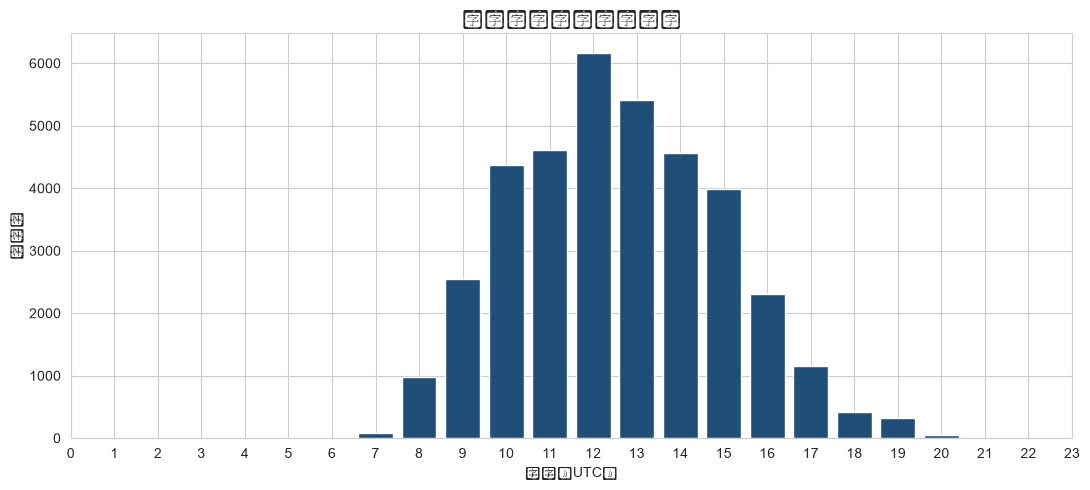


下单最高峰时段: 12:00（订单数 6170）


In [5]:
hour_order = df.groupby('Hour')['Invoice'].nunique()

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(hour_order.index, hour_order.values, color='#1F4E79')
ax.set_title('一天各小时订单量分布', fontsize=14, fontweight='bold')
ax.set_xlabel('小时（UTC）')
ax.set_ylabel('订单数')
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.savefig('../outputs/04_hour_dist.png', dpi=150, bbox_inches='tight')
plt.show()

peak_hour = hour_order.idxmax()
print(f'\n下单最高峰时段: {peak_hour}:00（订单数 {hour_order.max()}）')

## 图 5：客户下单次数分布（长尾）

C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\3717636735.py:10: UserWarning: Glyph 19979 (\N{CJK UNIFIED IDEOGRAPH-4E0B}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\3717636735.py:10: UserWarning: Glyph 21333 (\N{CJK UNIFIED IDEOGRAPH-5355}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\3717636735.py:10: UserWarning: Glyph 27425 (\N{CJK UNIFIED IDEOGRAPH-6B21}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\3717636735.py:10: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\3717636735.py:10: UserWarning: Glyph 23458 (\N{CJK UNIFIED IDEOGRAPH-5BA2}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\3717636735.py:10: UserWarning: Glyph 25143 (\N{CJK 

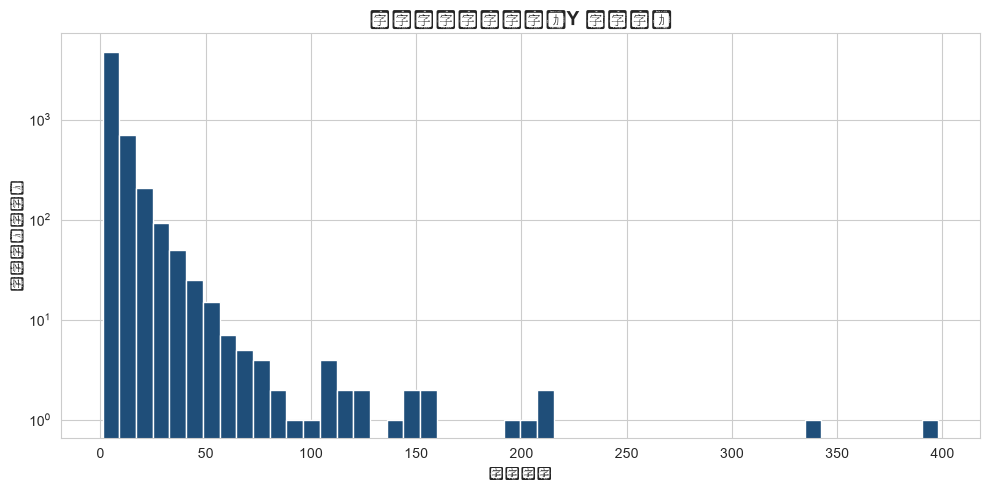


下单次数描述统计:
count    5878.00
mean        6.29
std        13.01
min         1.00
25%         1.00
50%         3.00
75%         7.00
max       398.00
Name: Invoice, dtype: float64

一次性客户（仅下 1 单）占比: 27.61%


In [6]:
customer_orders = df.groupby('Customer ID')['Invoice'].nunique()

fig, ax = plt.subplots(figsize=(10, 5))
# 用对数坐标看长尾更清楚
ax.hist(customer_orders, bins=50, color='#1F4E79', edgecolor='white')
ax.set_yscale('log')
ax.set_title('客户下单次数分布（Y 轴对数）', fontsize=14, fontweight='bold')
ax.set_xlabel('下单次数')
ax.set_ylabel('客户数（对数）')
plt.tight_layout()
plt.savefig('../outputs/05_order_count_dist.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n下单次数描述统计:')
print(customer_orders.describe().round(2))
print(f'\n一次性客户（仅下 1 单）占比: {(customer_orders == 1).sum() / len(customer_orders) * 100:.2f}%')

**观察点**：典型的长尾——少数客户贡献大部分订单，这是做 RFM 分层的核心价值所在。

## 图 6：单客户总消费金额分布

C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2658041455.py:9: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2658041455.py:9: UserWarning: Glyph 28040 (\N{CJK UNIFIED IDEOGRAPH-6D88}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2658041455.py:9: UserWarning: Glyph 36153 (\N{CJK UNIFIED IDEOGRAPH-8D39}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2658041455.py:9: UserWarning: Glyph 37329 (\N{CJK UNIFIED IDEOGRAPH-91D1}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2658041455.py:9: UserWarning: Glyph 39069 (\N{CJK UNIFIED IDEOGRAPH-989D}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_34456\2658041455.py:9: UserWarning: Glyph 23458 (\N{CJK UNIFIE

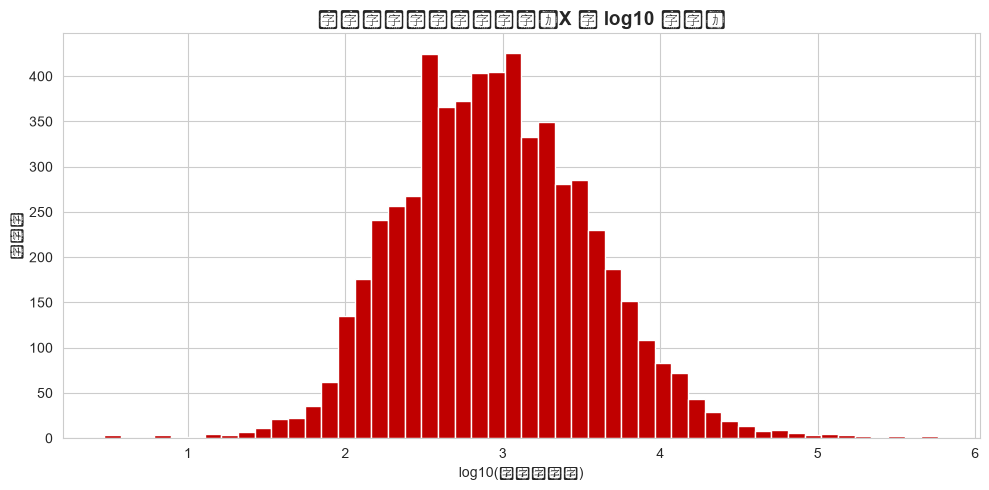


客户消费金额描述统计（英镑）:
count      5878.00
mean       2955.90
std       14440.85
min           2.95
25%         342.28
50%         867.74
75%        2248.30
max      580987.04
Name: TotalPrice, dtype: float64

Top 20% 客户贡献销售额占比: 77.23%（经典二八法则验证）


In [7]:
customer_spend = df.groupby('Customer ID')['TotalPrice'].sum()

# 用 log scale 把右端拉伸出来
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(np.log10(customer_spend.clip(lower=1)), bins=50, color='#C00000', edgecolor='white')
ax.set_title('单客户总消费金额分布（X 轴 log10 英镑）', fontsize=14, fontweight='bold')
ax.set_xlabel('log10(总消费金额)')
ax.set_ylabel('客户数')
plt.tight_layout()
plt.savefig('../outputs/06_customer_spend_dist.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n客户消费金额描述统计（英镑）:')
print(customer_spend.describe().round(2))

# 二八法则验证：Top 20% 客户贡献多少销售额
n_top = int(len(customer_spend) * 0.2)
top_20_share = customer_spend.nlargest(n_top).sum() / customer_spend.sum()
print(f'\nTop 20% 客户贡献销售额占比: {top_20_share * 100:.2f}%（经典二八法则验证）')

---

**EDA 到此结束**。6 张图都存在 `../outputs/` 下，面试可以直接截图或导入 PPT。

**下一步**：`04_rfm.ipynb` 做 RFM 建模与人群分层。